# Gap visualizations

Deliverable +6 (added from course reviewer feedback): visualizations to
make the gap analysis in [`analysis/gap-analysis.md`](../analysis/gap-analysis.md)
legible without having to read raw SPARQL output.

This notebook does not define any new findings - it re-runs the queries
already in [`../queries/`](../queries/) against the live
[Wikidata Query Service](https://query.wikidata.org/) and charts the
results. If the underlying data changes, re-running this notebook
re-generates the charts from scratch; nothing here is hand-drawn.

Dependencies: `pandas`, `matplotlib`, `requests` (see `../requirements.txt`).


In [1]:
import re
import time
from pathlib import Path

import pandas as pd
import requests
import matplotlib.pyplot as plt

ENDPOINT = "https://query.wikidata.org/sparql"
HEADERS = {
    "Accept": "application/sparql-results+json",
    "User-Agent": "plant-knowledge-wiki/0.1 (https://github.com/elenadelpup/plant-knowledge-wiki)",
}
QUERIES_DIR = Path("..") / "queries"

# Muted, print-friendly palette matching the project slide deck.
COLOR_BASE = "#3F6659"
COLOR_ANY = "#8E7A4A"
COLOR_REAL = "#C9622B"
COLOR_TEXT = "#1F2E24"


def load_query(filename):
    """Read a .rq file and strip full-line comments (# ...), including
    the commented-out follow-up query some files keep at the bottom."""
    text = (QUERIES_DIR / filename).read_text()
    lines = [ln for ln in text.splitlines() if not ln.strip().startswith("#")]
    return "\n".join(lines).strip()


def run_query(filename, retries=3):
    query = load_query(filename)
    last_exc = None
    for attempt in range(retries):
        try:
            resp = requests.get(
                ENDPOINT, params={"query": query}, headers=HEADERS, timeout=90
            )
            resp.raise_for_status()
            data = resp.json()
            bindings = data["results"]["bindings"]
            rows = []
            for b in bindings:
                row = {k: v.get("value") for k, v in b.items()}
                rows.append(row)
            return pd.DataFrame(rows)
        except Exception as exc:  # noqa: BLE001
            last_exc = exc
            time.sleep(2 * (attempt + 1))
    raise last_exc


## 1. Cross-species coverage

Re-runs [`03_multispecies_compound_pathway_coverage.rq`](../queries/03_multispecies_compound_pathway_coverage.rq):
for each species, how many compounds found in it (LOTUS-style `found in
taxon`, P703) have *any* `has part(s)` (P527) backlink versus a backlink
to a *genuine* WikiPathways-sourced pathway (P527 + P2410).

In [2]:
df_species = run_query("03_multispecies_compound_pathway_coverage.rq")
for col in ["compoundsTotal", "compoundsAnyP527", "compoundsRealPathway"]:
    df_species[col] = df_species[col].astype(int)
df_species["pct_any"] = 100 * df_species["compoundsAnyP527"] / df_species["compoundsTotal"]
df_species["pct_real"] = 100 * df_species["compoundsRealPathway"] / df_species["compoundsTotal"]
df_species = df_species.sort_values("pct_real").reset_index(drop=True)
df_species[["taxonLabel", "compoundsTotal", "compoundsAnyP527", "pct_any", "compoundsRealPathway", "pct_real"]]


,taxonLabel,compoundsTotal,compoundsAnyP527,pct_any,compoundsRealPathway,pct_real
0,Camellia sinensis,713,114,15.988780,29,4.067321
1,Brassica rapa,281,61,21.708185,22,7.829181
2,Arabidopsis thaliana,1284,225,17.523364,118,9.190031
3,Coffea arabica,205,60,29.268293,25,12.195122
4,Brassica oleracea,258,68,26.356589,46,17.829457
5,Theobroma cacao,142,63,44.366197,34,23.943662


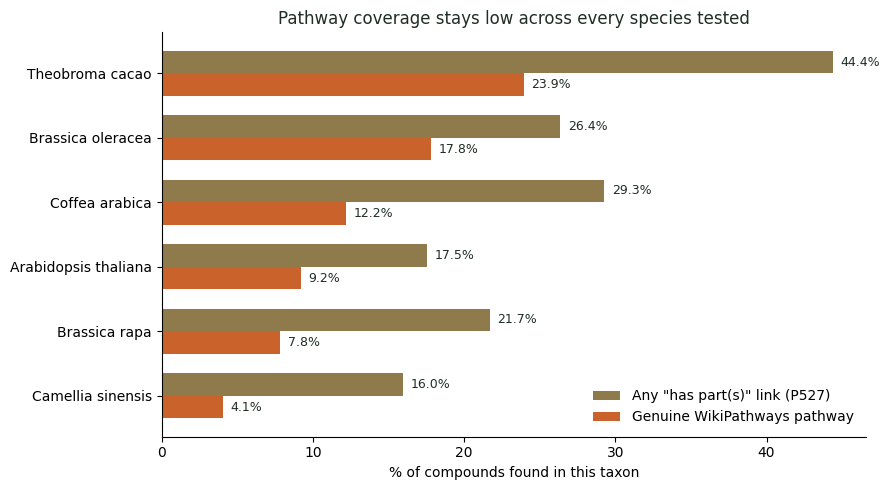

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
y = range(len(df_species))
bar_h = 0.35

ax.barh([i + bar_h / 2 for i in y], df_species["pct_any"], height=bar_h,
        color=COLOR_ANY, label="Any \"has part(s)\" link (P527)")
ax.barh([i - bar_h / 2 for i in y], df_species["pct_real"], height=bar_h,
        color=COLOR_REAL, label="Genuine WikiPathways pathway")

ax.set_yticks(list(y))
ax.set_yticklabels(df_species["taxonLabel"])
ax.set_xlabel("% of compounds found in this taxon")
ax.set_title("Pathway coverage stays low across every species tested", color=COLOR_TEXT)
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
for i, (pct_any, pct_real) in enumerate(zip(df_species["pct_any"], df_species["pct_real"])):
    ax.text(pct_any + 0.5, i + bar_h / 2, f"{pct_any:.1f}%", va="center", fontsize=9, color=COLOR_TEXT)
    ax.text(pct_real + 0.5, i - bar_h / 2, f"{pct_real:.1f}%", va="center", fontsize=9, color=COLOR_TEXT)

plt.tight_layout()
plt.savefig("species_coverage.png", dpi=150)
plt.show()


## 2. Case study: what does Wikidata actually link to caffeine?

Re-runs [`04_caffeine_case_study.rq`](../queries/04_caffeine_case_study.rq):
every item linked to caffeine (Q60235) via `has part(s)` (P527), the only
property currently usable as an (indirect) compound -> pathway link.

The category for each item below is a **manual classification**, done by
reading each item's label after running the live query (recorded here so
it's reproducible, not an automated inference). Re-running the query may
return additional items added to Wikidata later; this mapping covers the
items found as of 2026-11-21 and labels anything new as `"uncategorized"`.

In [4]:
df_caffeine = run_query("04_caffeine_case_study.rq")
print(f"{len(df_caffeine)} distinct items link to caffeine via P527")
df_caffeine.head()


48 distinct items link to caffeine via P527


,pathway,pathwayLabel,wikipathwaysId
0,http://www.wikidata.org/entity/Q2839379,Q2839379,NaN
1,http://www.wikidata.org/entity/Q2974480,caffeine citrate,NaN
2,http://www.wikidata.org/entity/Q1062396,cocoa powder,NaN
3,http://www.wikidata.org/entity/Q3959196,Shark,NaN
4,http://www.wikidata.org/entity/Q5017160,caffeinated drink,NaN


In [5]:
CATEGORY_BY_QID = {
    # consumer products / drinks
    "http://www.wikidata.org/entity/Q2839379": "Consumer product / drink",  # Alp'Cola (French label only)
    "http://www.wikidata.org/entity/Q113495133": "Consumer product / drink", # instance of "human food" (Q8195619)
    "http://www.wikidata.org/entity/Q1062396": "Consumer product / drink",   # cocoa powder
    "http://www.wikidata.org/entity/Q3959196": "Consumer product / drink",   # Shark (energy drink)
    "http://www.wikidata.org/entity/Q5017160": "Consumer product / drink",   # caffeinated drink
    "http://www.wikidata.org/entity/Q1107571": "Consumer product / drink",   # Cola Turka
    "http://www.wikidata.org/entity/Q5275050": "Consumer product / drink",   # Diet Pepsi
    "http://www.wikidata.org/entity/Q1794027": "Consumer product / drink",   # Dark Dog
    "http://www.wikidata.org/entity/Q11812236": "Consumer product / drink", # Dinyl
    "http://www.wikidata.org/entity/Q257260": "Consumer product / drink",   # OpenCola
    "http://www.wikidata.org/entity/Q2994603": "Consumer product / drink",  # BAWLS Guarana
    "http://www.wikidata.org/entity/Q3430917": "Consumer product / drink",  # Mad-Croc
    "http://www.wikidata.org/entity/Q3493770": "Consumer product / drink",  # Pepsi Max
    "http://www.wikidata.org/entity/Q4983112": "Consumer product / drink",  # Buckfast Tonic Wine
    "http://www.wikidata.org/entity/Q8181650": "Consumer product / drink",  # Acylcoffin
    "http://www.wikidata.org/entity/Q6097": "Consumer product / drink",     # tea (the drink)
    "http://www.wikidata.org/entity/Q51482": "Consumer product / drink",    # Red Bull
    "http://www.wikidata.org/entity/Q65073889": "Consumer product / drink", # G Fuel
    "http://www.wikidata.org/entity/Q116150464": "Consumer product / drink",# Bela-Cola
    # drug combination products
    "http://www.wikidata.org/entity/Q2974480": "Drug / drug combination",   # caffeine citrate
    "http://www.wikidata.org/entity/Q2292614": "Drug / drug combination",   # ya ba
    "http://www.wikidata.org/entity/Q2537288": "Drug / drug combination",   # propyphenazone/paracetamol/caffeine
    "http://www.wikidata.org/entity/Q5767602": "Drug / drug combination",   # aspirin/paracetamol/caffeine
    "http://www.wikidata.org/entity/Q48566629": "Drug / drug combination",
    "http://www.wikidata.org/entity/Q48566647": "Drug / drug combination",
    "http://www.wikidata.org/entity/Q48566639": "Drug / drug combination",
    "http://www.wikidata.org/entity/Q48566667": "Drug / drug combination",
    "http://www.wikidata.org/entity/Q48566676": "Drug / drug combination",
    "http://www.wikidata.org/entity/Q48566747": "Drug / drug combination",
    "http://www.wikidata.org/entity/Q48566815": "Drug / drug combination",  # caffeine/ergotamine
    # genuine WikiPathways pathways - all human pharmacology/physiology
    "http://www.wikidata.org/entity/Q30231004": "Human pathway (WikiPathways)",  # DNA damage response, WP707
    "http://www.wikidata.org/entity/Q30225374": "Human pathway (WikiPathways)",  # miRNA reg. of DNA damage response, WP1530
    "http://www.wikidata.org/entity/Q44056878": "Human pathway (WikiPathways)",  # miRNA reg. of DNA Damage Response, WP2087
    "http://www.wikidata.org/entity/Q54990085": "Human pathway (WikiPathways)",  # Phosphodiesterases in neuronal function, WP4222
    "http://www.wikidata.org/entity/Q102720615": "Human pathway (WikiPathways)", # Purinergic signaling, WP4900
    "http://www.wikidata.org/entity/Q28869950": "Human pathway (WikiPathways)",  # caffeine and theobromine metabolism, WP3633 - tagged to archaic Homo sapiens
    # enzyme/biochemical activity or GO-style terms, no taxon attached
    "http://www.wikidata.org/entity/Q14864406": "Enzyme/GO activity term (no taxon)",  # caffeine oxidase activity
    "http://www.wikidata.org/entity/Q14865217": "Enzyme/GO activity term (no taxon)",  # response to caffeine
    "http://www.wikidata.org/entity/Q21100531": "Enzyme/GO activity term (no taxon)",  # cellular response to caffeine
    "http://www.wikidata.org/entity/Q27124976": "Enzyme/GO activity term (no taxon)",  # theobromine:SAM 1-N-methyltransferase activity
    "http://www.wikidata.org/entity/Q27863054": "Enzyme/GO activity term (no taxon)",  # paraxanthine:SAM 3-N-methyltransferase activity
    "http://www.wikidata.org/entity/Q50295270": "Enzyme/GO activity term (no taxon)",  # N-atom dealkylation of caffeine
    # taste receptor ligand entries
    "http://www.wikidata.org/entity/Q50272837": "Taste receptor ligand entry",   # Bitter-tasting compounds [extracellular region]
    "http://www.wikidata.org/entity/Q112977494": "Taste receptor ligand entry",  # Ligand of TAS2R46
    "http://www.wikidata.org/entity/Q112977492": "Taste receptor ligand entry",  # Ligand of TAS2R7
    "http://www.wikidata.org/entity/Q112977500": "Taste receptor ligand entry",  # Ligand of TAS2R14
    "http://www.wikidata.org/entity/Q112977505": "Taste receptor ligand entry",  # Ligand of TAS2R43
    "http://www.wikidata.org/entity/Q112977511": "Taste receptor ligand entry",  # Ligand of TAS2R10
}

df_caffeine["category"] = df_caffeine["pathway"].map(CATEGORY_BY_QID).fillna("uncategorized")
df_caffeine.loc[df_caffeine["category"] == "uncategorized", ["pathway", "pathwayLabel"]]


,pathway,pathwayLabel


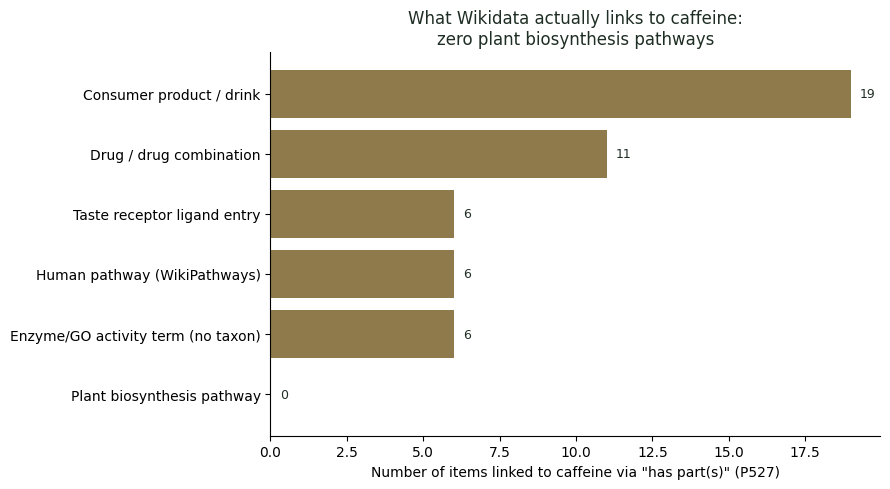

In [6]:
counts = df_caffeine["category"].value_counts()
# Make the absence of the category we actually care about visible on the chart.
counts["Plant biosynthesis pathway"] = counts.get("Plant biosynthesis pathway", 0)
counts = counts.sort_values()

colors = [COLOR_REAL if cat == "Plant biosynthesis pathway" else COLOR_ANY for cat in counts.index]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(counts.index, counts.values, color=colors)
ax.set_xlabel("Number of items linked to caffeine via \"has part(s)\" (P527)")
ax.set_title(
    "What Wikidata actually links to caffeine:\nzero plant biosynthesis pathways",
    color=COLOR_TEXT,
)
ax.spines[["top", "right"]].set_visible(False)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height() / 2, str(val),
            va="center", fontsize=9, color=COLOR_TEXT)

plt.tight_layout()
plt.savefig("caffeine_case_study.png", dpi=150)
plt.show()


## Takeaways

- Pathway coverage is low (under ~24%) for every species tested so far,
  not just Arabidopsis - see [`analysis/gap-analysis.md`](../analysis/gap-analysis.md#coverage-across-species-is-the-gap-arabidopsis-specific).
- Of everything Wikidata links to caffeine via the only property currently
  usable for this (`has part(s)`, P527), **zero** items are a plant
  biosynthesis pathway - the project's own coffee/tea/cacao example is
  empirically confirmed, not just illustrative.

**Next for this notebook:** once the qualifier-usage survey (Objective 4,
still open) has a query in `../queries/`, add a third chart here showing
how rarely `found in taxon` (P703), `anatomical location` (P927),
`determination method` (P459) etc. are actually used as qualifiers on the
relevant statements.